# 1. Probability Distribution Function of Sentinel data

### Accesing data from S1 and S2 for natural and urban areas

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
S2_FILES = {"Natural area": "Sentinel2_RGB_Nature.tif", "Urban area": "Sentinel2_RGB_City.tif"}
S2_BANDS = {"B2 (blue)": 3, "B3 (green)": 2, "B4 (red)": 1}

S1_FILES = {"Natural area": "Sentinel1_VV_Nature.tif", "Urban area": "Sentinel1_VV_City.tif"}
S1_BANDS = {"VV (dB)": 1}

### Drawing histograms of S1 and S2 images

In [2]:
def read_selected_bands(path, band_map):
    if path is None or not Path(path).is_file():
        raise FileNotFoundError(
            f"Set a valid GeoTIFF path first. Received: {path!r}. "
        )
    result = {}
    with rasterio.open(path) as src:
        for name, index in band_map.items():
            if not 1 <= index <= src.count:
                raise ValueError(f"Band index {index} for {name} is outside 1..{src.count} in {path}")
            arr = src.read(index).astype(np.float64)
            if src.nodata is not None:
                arr[arr == src.nodata] = np.nan
            result[name] = arr
    return result

def report_stats(arr):
    x = arr[np.isfinite(arr)]
    if x.size == 0:
        return None
    return {"valid_pixels": int(x.size), "mean": float(np.mean(x)),
            "median": float(np.median(x)), "std": float(np.std(x)),
            "min": float(np.min(x)), "max": float(np.max(x))}

def plot_empirical_pdfs(file_map, band_map, title, bins=256):
    loaded = {site: read_selected_bands(path, band_map) for site, path in file_map.items()}
    fig, axes = plt.subplots(len(band_map), 1, figsize=(10, 3.2 * len(band_map)), squeeze=False)
    for ax, band in zip(axes[:, 0], band_map):
        for site, data in loaded.items():
            x = data[band][np.isfinite(data[band])]
            ax.hist(x, bins=bins, weights=np.ones(x.size) / x.size,
                    alpha=0.55, label=site, histtype="stepfilled")
        ax.set_title(band)
        ax.set_xlabel("Pixel value")
        ax.set_ylabel("Probability per bin")
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    for site, data in loaded.items():
        print(f"\n{site}")
        for band, arr in data.items():
            print(band, report_stats(arr))
    return loaded


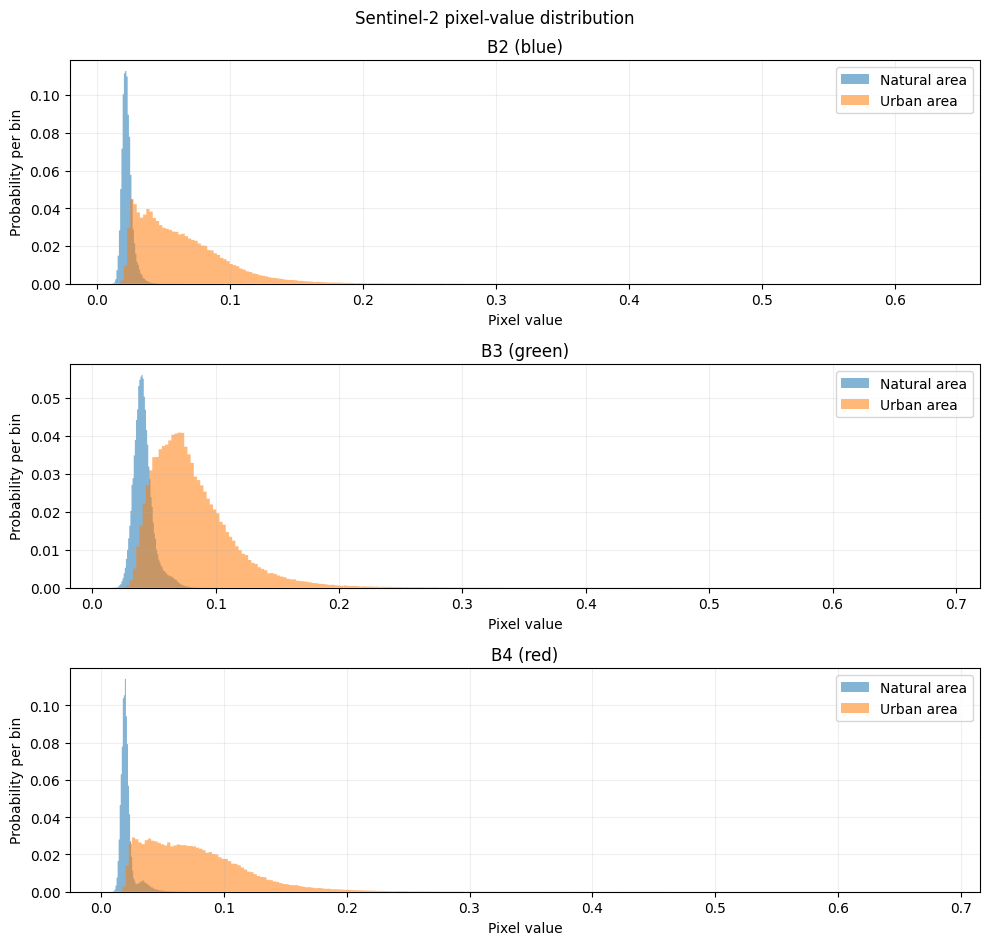


Natural area
B2 (blue) {'valid_pixels': 384779, 'mean': 0.02265625428675791, 'median': 0.022050000727176666, 'std': 0.004302905971491037, 'min': 0.01080000028014183, 'max': 0.251800000667572}
B3 (green) {'valid_pixels': 384779, 'mean': 0.04140509338218411, 'median': 0.04039999842643738, 'std': 0.00837377235564936, 'min': 0.015399999916553497, 'max': 0.24719999730587006}
B4 (red) {'valid_pixels': 384779, 'mean': 0.021067766224072842, 'median': 0.019700000062584877, 'std': 0.006534882321028208, 'min': 0.00839999970048666, 'max': 0.2248000055551529}

Urban area
B2 (blue) {'valid_pixels': 347434, 'mean': 0.063815646202445, 'median': 0.05620000138878822, 'std': 0.03594065924814574, 'min': 0.015350000001490116, 'max': 0.6327999830245972}
B3 (green) {'valid_pixels': 347434, 'mean': 0.08193852522614707, 'median': 0.07460000365972519, 'std': 0.03532668075181328, 'min': 0.022600000724196434, 'max': 0.6859999895095825}
B4 (red) {'valid_pixels': 347434, 'mean': 0.07773987598593596, 'median': 0.07

In [3]:
s2 = plot_empirical_pdfs(S2_FILES, S2_BANDS, "Sentinel-2 pixel-value distribution")

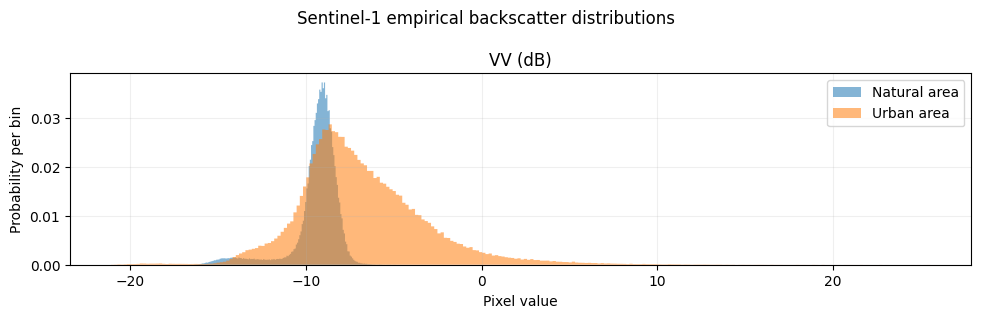


Natural area
VV (dB) {'valid_pixels': 384779, 'mean': -9.42066327172419, 'median': -9.149870651821224, 'std': 1.3976679520483006, 'min': -17.18181210394596, 'max': -0.10097806531947007}

Urban area
VV (dB) {'valid_pixels': 347434, 'mean': -6.8581913475638645, 'median': -7.407385485016043, 'std': 3.6529221723242977, 'min': -21.096766093065114, 'max': 25.546358326660837}


In [4]:
s1 = plot_empirical_pdfs(S1_FILES, S1_BANDS, "Sentinel-1 empirical backscatter distributions")

### Observations

Sentinel-2:
The urban area had higher mean reflectance than the natural area in all three bands: B2, B3, and B4. Its histograms were also broader, indicating greater variation in surface types and stronger reflectance within the urban image.

Sentinel-1: The urban area shows higher VV backscatter and a wider histogram than the natural area, indicating stronger and more variable return. This may reflect the greater diversity of buildings and other surfaces in the urban scene.

# Stereography

### Replacing the last two LSB

In [5]:
site_for_stego, band_for_stego = "Urban area", "B4 (red)"
reflectance = s2[site_for_stego][band_for_stego]
valid = np.isfinite(reflectance)
scale = 10_000  # explicit reflectance-to-DN quantization
if np.nanmin(reflectance) < 0 or np.nanmax(reflectance) > 1:
    raise ValueError("Expected reflectance in [0,1]; inspect the source scale before quantizing.")
original_u16 = np.zeros(reflectance.shape, dtype=np.uint16)
original_u16[valid] = np.rint(reflectance[valid] * scale).astype(np.uint16)
rng = np.random.default_rng(2026)  # reproducible random values, independently generated per pixel
random_two_bits = rng.integers(0, 4, size=reflectance.shape, dtype=np.uint16)
manipulated_u16 = (original_u16 & np.uint16(0xFFFC)) | random_two_bits
manipulated_u16[~valid] = original_u16[~valid]
changed = valid & (original_u16 != manipulated_u16)
print(f"Valid pixels: {valid.sum():,}")
print(f"Changed pixels: {changed.sum():,} ({100 * changed.sum() / valid.sum():.2f}%)")
print(f"Maximum absolute change: {np.max(np.abs(original_u16[valid].astype(np.int32) - manipulated_u16[valid].astype(np.int32)))} DN")
print(f"Maximum change at this scale: {3 / scale:.4f} reflectance")

Valid pixels: 347,434
Changed pixels: 260,490 (74.98%)
Maximum absolute change: 3 DN
Maximum change at this scale: 0.0003 reflectance


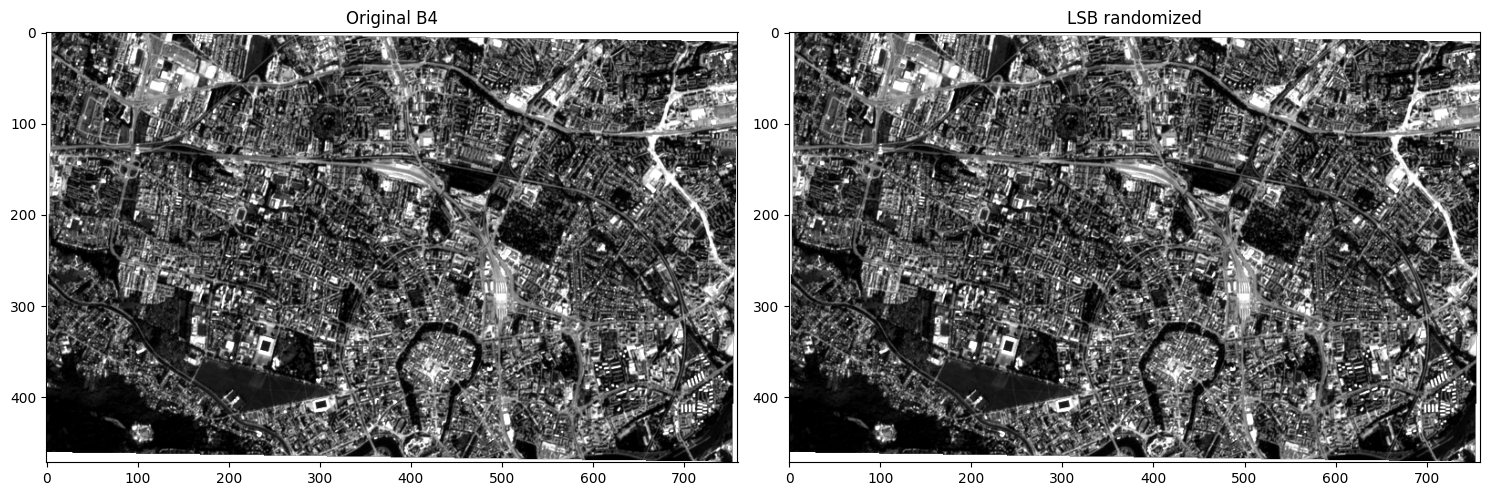

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orig_ref, manip_ref = original_u16.astype(float)/scale, manipulated_u16.astype(float)/scale
diff_ref = np.abs(original_u16.astype(np.int32)-manipulated_u16.astype(np.int32))/scale
vmin, vmax = np.percentile(reflectance[valid], [2, 98])
axes[0].imshow(np.where(valid, orig_ref, np.nan), cmap="gray", vmin=vmin, vmax=vmax); axes[0].set_title("Original B4")
axes[1].imshow(np.where(valid, manip_ref, np.nan), cmap="gray", vmin=vmin, vmax=vmax); axes[1].set_title("LSB randomized")
fig.tight_layout(); plt.show()


### Ploting histogram of original and manipulated images

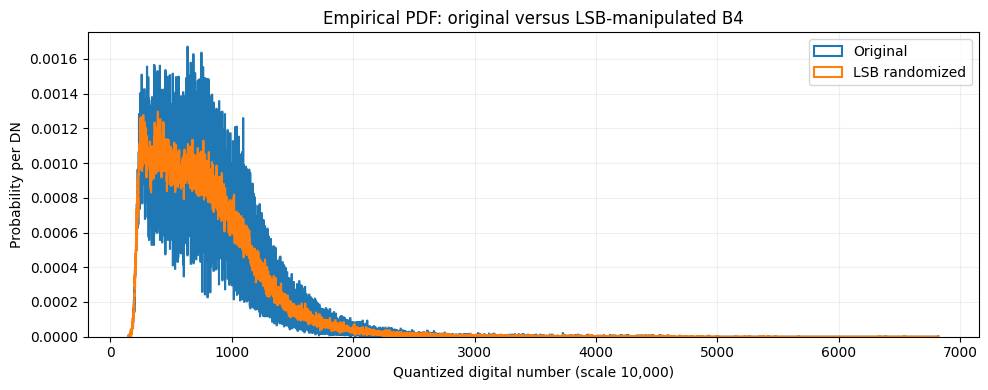

Mean DN original / manipulated: 777.3972265235988 777.546472135715
Std DN original / manipulated: 437.26407152622164 437.3455784876667
Exact histogram equality: False


In [7]:
vals_original, vals_manipulated = original_u16[valid], manipulated_u16[valid]
lo, hi = int(min(vals_original.min(), vals_manipulated.min())), int(max(vals_original.max(), vals_manipulated.max()))
bin_edges = np.arange(lo, hi + 2) - 0.5
plt.figure(figsize=(10, 4))
plt.hist(vals_original, bins=bin_edges, weights=np.ones(vals_original.size)/vals_original.size, histtype="step", linewidth=1.5, label="Original")
plt.hist(vals_manipulated, bins=bin_edges, weights=np.ones(vals_manipulated.size)/vals_manipulated.size, histtype="step", linewidth=1.5, label="LSB randomized")
plt.xlabel("Quantized digital number (scale 10,000)"); plt.ylabel("Probability per DN")
plt.title("Empirical PDF: original versus LSB-manipulated B4")
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()
print("Mean DN original / manipulated:", float(vals_original.mean()), float(vals_manipulated.mean()))
print("Std DN original / manipulated:", float(vals_original.std()), float(vals_manipulated.std()))
print("Exact histogram equality:", np.array_equal(np.bincount(vals_original.astype(np.int64), minlength=hi+1), np.bincount(vals_manipulated.astype(np.int64), minlength=hi+1)))


### Differences and conclusions

Replacing the two least significant bits changes most pixel values slightly, so the image looks almost identical. The original and modified histograms are visibyly different, it may help flag possible manipulation.